# Credit Card Fraud Detection: 3-model comparison

<div dir="rtl">

مراحل کار: بررسی داده ← تقسیم train/test ← مقایسهٔ سه مدل (Logistic Regression، Random Forest، XGBoost) با اعتبارسنجی متقابل ← انتخاب آستانه ← ارزیابی نهایی روی test ← ذخیرهٔ مدل.

نیازمندی‌ها: `pip install xgboost` (بقیهٔ کتابخانه‌ها: numpy، pandas، matplotlib، scikit-learn، joblib).

</div>

In [4]:
import json
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost
from xgboost import XGBClassifier
from joblib import dump
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix, classification_report,
)

print("Path to dataset files:", path)
SEED = 42

np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7, 5)

Path to dataset files: /kaggle/input/datasets/mlg-ulb/creditcardfraud


## 1. Load data and quick look

In [6]:
import os
import pandas as pd

df = pd.read_csv(os.path.join(path, "creditcard.csv"))

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081


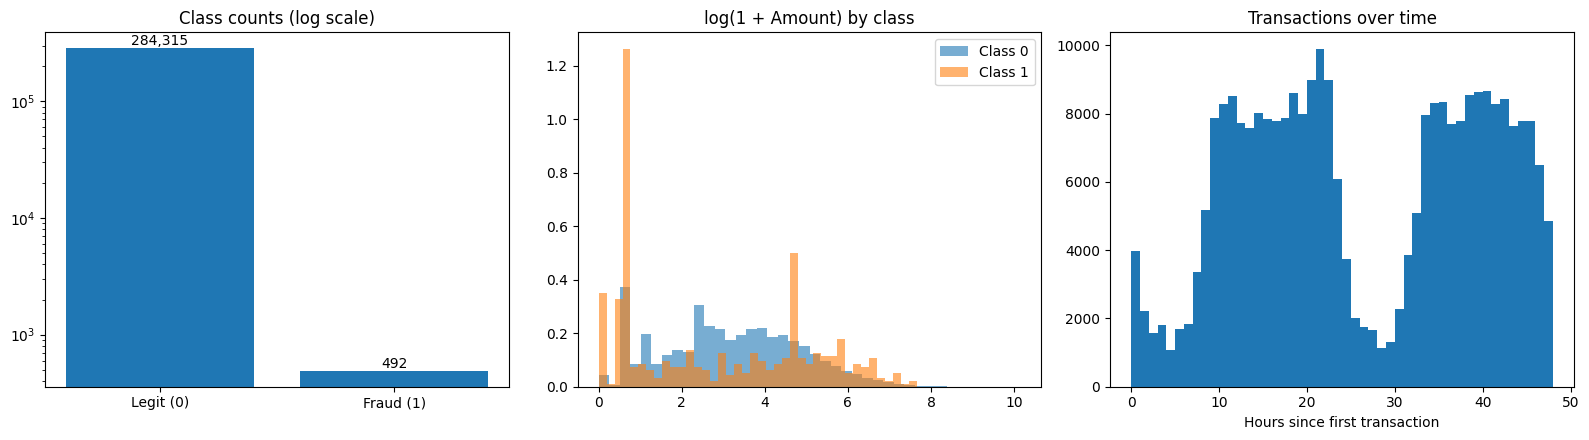

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) class imbalance (log scale, otherwise the fraud bar is invisible)
counts = df["Class"].value_counts().sort_index()
axes[0].bar(["Legit (0)", "Fraud (1)"], counts.values)
axes[0].set_yscale("log")
axes[0].set_title("Class counts (log scale)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# 2) amount per class (log1p because Amount is heavily right-skewed)
for label, grp in df.groupby("Class"):
    axes[1].hist(np.log1p(grp["Amount"]), bins=40, alpha=0.6, density=True, label=f"Class {label}")
axes[1].set_title("log(1 + Amount) by class")
axes[1].legend()

# 3) time distribution
axes[2].hist(df["Time"] / 3600, bins=48)
axes[2].set_title("Transactions over time")
axes[2].set_xlabel("Hours since first transaction")

plt.tight_layout()
plt.show()

## 2. Train / test split

<div dir="rtl">

۸۰٪ آموزش و ۲۰٪ آزمون، با حفظ نسبت تقلب در هر دو بخش. مجموعهٔ test فقط یک بار و در انتها برای ارزیابی نهایی استفاده می‌شود.

</div>

In [8]:
y = df["Class"].astype(int).values
X = df.drop(columns=["Class"])

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(sss.split(X, y))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]

print("Train:", X_train.shape, "| frauds:", int(y_train.sum()))
print("Test: ", X_test.shape, "| frauds:", int(y_test.sum()))

Train: (227845, 30) | frauds: 394
Test:  (56962, 30) | frauds: 98


## 3. Preprocessing and the three models

<div dir="rtl">

فقط `Amount` و `Time` استاندارد می‌شوند. ستون‌های `V1` تا `V28` خروجی PCA هستند و دست‌نخورده عبور می‌کنند. هر سه مدل عدم‌توازن کلاس‌ها را با وزن‌دهی جبران می‌کنند:

- Logistic Regression و Random Forest: `class_weight`
- XGBoost: `scale_pos_weight` (نسبت نمونه‌های سالم به تقلب)

</div>

In [10]:
pre = ColumnTransformer(
    [("scale", StandardScaler(), ["Amount", "Time"])],
    remainder="passthrough",
)

neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
pos_weight = neg / pos
print(f"scale_pos_weight = {pos_weight:.1f}")

models = {
    "logreg": LogisticRegression(
        max_iter=1000, class_weight="balanced",
    ),
    "rf": RandomForestClassifier(
        n_estimators=150, max_depth=18, max_samples=0.5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
    ),
    "xgb": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=pos_weight,
        eval_metric="aucpr", tree_method="hist",
        n_jobs=-1, random_state=SEED,
    ),
}


def make_pipe(clf):
    return Pipeline([("pre", pre), ("clf", clf)])

scale_pos_weight = 577.3


## 4. Compare models with 5-fold cross-validation (train set only)

<div dir="rtl">

برای انتخاب مدل و آستانه از مجموعهٔ test استفاده نمی‌کنیم. به‌جایش برای هر نمونهٔ آموزشی یک پیش‌بینی «out-of-fold» می‌گیریم (مدلی که آن نمونه را ندیده)، و روی آن‌ها:

1. معیارهای AP و ROC-AUC حساب می‌شود،
2. آستانهٔ بهینه برای F1 پیدا می‌شود.

مدل برتر بر اساس **Average Precision** انتخاب می‌شود، چون برای داده‌ی بسیار نامتوازن معنادارتر از ROC-AUC است.

</div>

In [11]:
def best_threshold_by_f1(y_true, proba):
    """Return (threshold, f1) that maximises F1 on the precision-recall curve."""
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)   # last PR point has no threshold
    i = int(np.argmax(f1))
    return float(t[i]), float(f1[i])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_proba, cv_rows = {}, []
for name, clf in models.items():
    print(f"Cross-validating {name} ...")
    proba = cross_val_predict(make_pipe(clf), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_proba[name] = proba
    thr, f1 = best_threshold_by_f1(y_train, proba)
    cv_rows.append({
        "model": name,
        "cv_AP": average_precision_score(y_train, proba),
        "cv_ROC_AUC": roc_auc_score(y_train, proba),
        "threshold": thr,
        "cv_F1@thr": f1,
    })

cv_table = pd.DataFrame(cv_rows).set_index("model")
best_name = cv_table["cv_AP"].idxmax()

print()
print(cv_table.round(4))
print("\nBest model by CV average precision:", best_name)

Cross-validating logreg ...
Cross-validating rf ...
Cross-validating xgb ...

         cv_AP  cv_ROC_AUC  threshold  cv_F1@thr
model                                           
logreg  0.7416      0.9815     1.0000     0.8087
rf      0.8327      0.9537     0.2133     0.8439
xgb     0.8481      0.9818     0.8420     0.8645

Best model by CV average precision: xgb


## 5. Final evaluation of all three models on the test set

<div dir="rtl">

هر سه مدل روی کل داده‌ی آموزشی دوباره آموزش می‌بینند و با آستانه‌ای که از اعتبارسنجی به‌دست آمد روی test ارزیابی می‌شوند. توجه: test فقط حدود ۱۰۰ تقلب دارد، پس اختلاف‌های کوچک بین مدل‌ها ممکن است فقط نوسان آماری باشد.

</div>

In [12]:
fitted, test_proba, test_rows = {}, {}, []
for name, clf in models.items():
    pipe = make_pipe(clf).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    thr = cv_table.loc[name, "threshold"]
    pred = (proba >= thr).astype(int)

    fitted[name], test_proba[name] = pipe, proba
    test_rows.append({
        "model": name,
        "test_AP": average_precision_score(y_test, proba),
        "test_ROC_AUC": roc_auc_score(y_test, proba),
        "threshold": thr,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "frauds_caught": int(((pred == 1) & (y_test == 1)).sum()),
        "false_alarms": int(((pred == 1) & (y_test == 0)).sum()),
    })

results = pd.DataFrame(test_rows).set_index("model").sort_values("test_AP", ascending=False)
print(f"Test set: {len(y_test):,} transactions, {int(y_test.sum())} frauds\n")
results.round(4)

Test set: 56,962 transactions, 98 frauds



,test_AP,test_ROC_AUC,threshold,precision,recall,F1,frauds_caught,false_alarms
model,,,,,,,,
xgb,0.8776,0.9808,0.8420,0.8876,0.8061,0.8449,79,10
rf,0.8511,0.9564,0.2133,0.8384,0.8469,0.8426,83,16
logreg,0.7159,0.9722,1.0000,0.8298,0.7959,0.8125,78,16


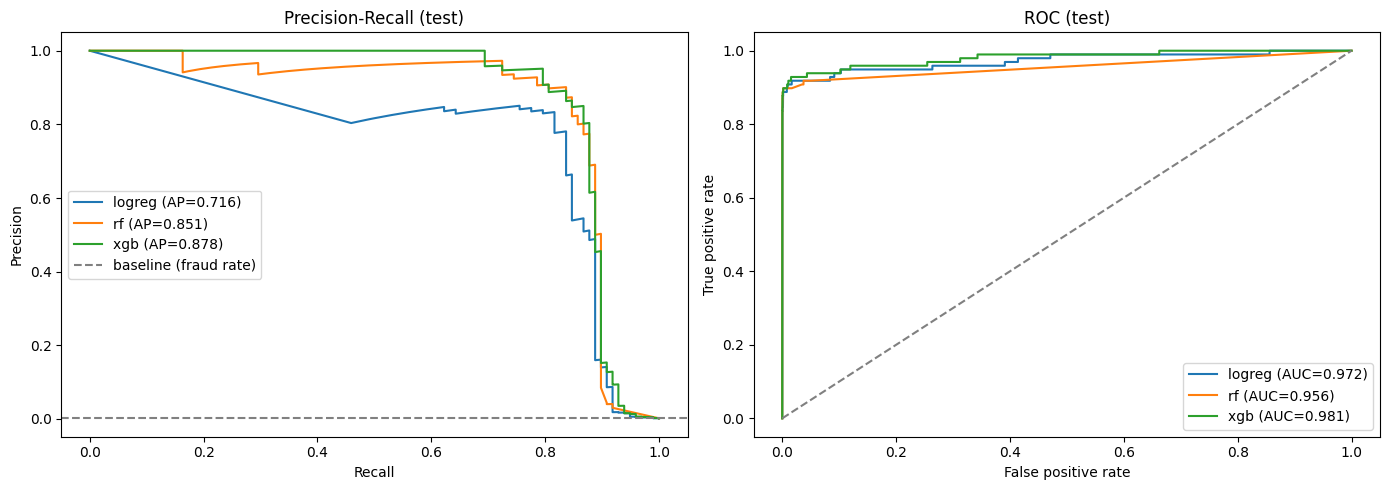

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in models:
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    axes[0].plot(rec, prec, label=f"{name} (AP={results.loc[name, 'test_AP']:.3f})")
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'test_ROC_AUC']:.3f})")

axes[0].axhline(y_test.mean(), ls="--", color="gray", label="baseline (fraud rate)")
axes[0].set(title="Precision-Recall (test)", xlabel="Recall", ylabel="Precision")
axes[0].legend()

axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="ROC (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Best model in detail

<div dir="rtl">

مدل برتر (انتخاب‌شده با اعتبارسنجی متقابل، نه با test) با آستانه‌ی بهینه‌اش.

</div>

Model: xgb | threshold = 0.842
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9997     56864
           1     0.8876    0.8061    0.8449        98

    accuracy                         0.9995     56962
   macro avg     0.9437    0.9030    0.9223     56962
weighted avg     0.9995    0.9995    0.9995     56962



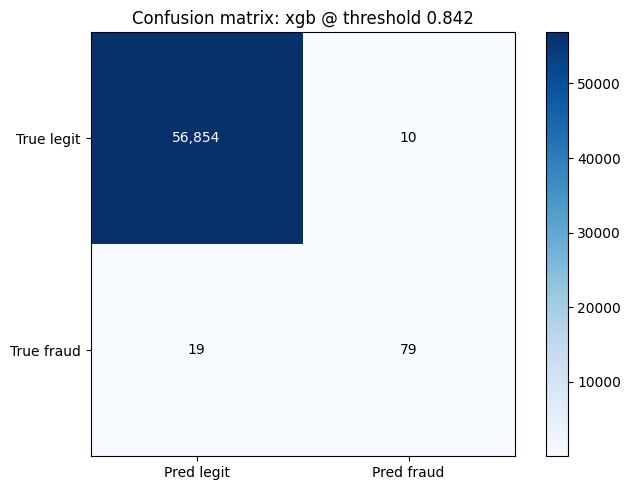

In [14]:
best_pipe = fitted[best_name]
best_thr = float(cv_table.loc[best_name, "threshold"])
y_pred = (test_proba[best_name] >= best_thr).astype(int)
cm = confusion_matrix(y_test, y_pred)

print(f"Model: {best_name} | threshold = {best_thr:.3f}")
print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots()
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["Pred legit", "Pred fraud"])
ax.set_yticks([0, 1], ["True legit", "True fraud"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"Confusion matrix: {best_name} @ threshold {best_thr:.3f}")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 7. Save the model

<div dir="rtl">

علاوه بر مدل، آستانهٔ بهینه و نسخهٔ کتابخانه‌ها هم ذخیره می‌شوند. بدون آستانه، مصرف‌کنندهٔ مدل مجبور است از ۰٫۵ استفاده کند.

</div>

In [15]:
models_dir = Path("models")
models_dir.mkdir(exist_ok=True, parents=True)

dump(best_pipe, models_dir / "model.joblib")

meta = {
    "algo": best_name,
    "threshold": best_thr,
    "trained_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "cv_average_precision": float(cv_table.loc[best_name, "cv_AP"]),
    "test_average_precision": float(results.loc[best_name, "test_AP"]),
    "test_roc_auc": float(results.loc[best_name, "test_ROC_AUC"]),
    "features": list(X.columns),
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
}
(models_dir / "metadata.json").write_text(json.dumps(meta, indent=2))
meta

{'algo': 'xgb',
 'threshold': 0.8420055508613586,
 'trained_at': '2026-11-24 08:03:29',
 'cv_average_precision': 0.848077814363208,
 'test_average_precision': 0.8775588501221334,
 'test_roc_auc': 0.9808393531864068,
 'features': ['Time',
  'V1',
  'V2',
  'V3',
  'V4',
  'V5',
  'V6',
  'V7',
  'V8',
  'V9',
  'V10',
  'V11',
  'V12',
  'V13',
  'V14',
  'V15',
  'V16',
  'V17',
  'V18',
  'V19',
  'V20',
  'V21',
  'V22',
  'V23',
  'V24',
  'V25',
  'V26',
  'V27',
  'V28',
  'Amount'],
 'sklearn_version': '1.6.1',
 'xgboost_version': '3.4.1'}

### Using the saved model

```python
from joblib import load
import json, pandas as pd

model = load("models/model.joblib")
meta = json.load(open("models/metadata.json"))

new_tx = pd.read_csv("new_transactions.csv")[meta["features"]]
fraud_flag = model.predict_proba(new_tx)[:, 1] >= meta["threshold"]
```